# CS 6470 A5 — Clustering for a business question

**50 points** · Module 11 · plan for about 3–4 focused hours

**Before you submit, rename this file to `CS6470_A5_LastName_FirstName.ipynb`.**
Open it in [Google Colab](https://colab.research.google.com/) (File → Upload notebook) or local Jupyter (Python 3.10+).

## How this notebook works

- It has **5 numbered tasks**, top to bottom. Cells marked **`# YOUR CODE`** and Markdown cells marked **YOUR ANSWER** are the graded work. Cells marked *Runs as-is* are provided — run them and read them.
- Every coding task ends with a **Checkpoint** describing what you should see, so you always know whether you are on track. Small differences (±0.01–0.02 on scores) are normal.
- **Hints name every class and argument.** Newer to Python? Follow them literally. Comfortable? Try each task from the description first. Experienced? There is an ungraded stretch at the end of the assignment page.
- A `# YOUR CODE` cell raises `NotImplementedError` until you replace that line — that is the notebook telling you where to work, not a bug.
- Before submitting: **Runtime → Restart and run all.** Every cell must run with no errors and no `NotImplementedError` left.


## Task 1 of 5 — State the business question first — YOUR ANSWER

Clustering will hand you groups no matter what — even in pure noise. The only defense is deciding **before you run it** what the groups would be *for*.

Fill in the template (2–4 sentences total):

**Who would act on these groups:** A marketing team would act on these groups. 

**What decision changes:** They could use the groups to decide which products to promote, what messaging to use, and what offers to send to different customers. 

**How many groups could that decision realistically use:** I think they could reasonably handle three groups as a starting point.


## Setup and data *(runs as-is)*

**Dataset: Wholesale customers** (UCI) — 440 clients of a wholesale distributor; six columns of **annual spend** by product category (`Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`, in monetary units).

Two columns are deliberately **excluded from clustering**: `Channel` (1 = horeca: hotel/restaurant/café, 2 = retail) and `Region` are pre-existing labels. If we clustered on them we would just "discover" them back. We hold `Channel` aside and use it in Task 4 as an honesty check on what the clusters found.


In [1]:
# Runs as-is — load the data, define the spend features.
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
df = pd.read_csv(url)
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
print("shape:", df.shape)
df.head()


shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## Task 2 of 5 — Scale, sweep k, plot silhouette

`Fresh` spend runs into the tens of thousands while `Delicassen` is in the hundreds — unscaled, one column would own every distance. Scale first, then sweep.

In code:

1. Scale the six spend columns with `StandardScaler` → an array `Xs`.
2. For `k` in 2…7: fit `KMeans(n_clusters=k, n_init=10, random_state=42)` and compute `silhouette_score(Xs, labels)`.
3. Plot k vs silhouette (a simple line plot with markers), with axis labels and a title.

**Hints.** `Xs = StandardScaler().fit_transform(df[spend_cols])` · `labels = km.fit_predict(Xs)` · collect scores in a list, then `plt.plot(range(2, 8), scores, marker="o")`.

**Checkpoint.** Silhouette ≈ **0.55** at k=2 and k=3 (nearly tied), then it drops hard to ≈ 0.35 at k=4 — the geometry prefers 2–3 groups.


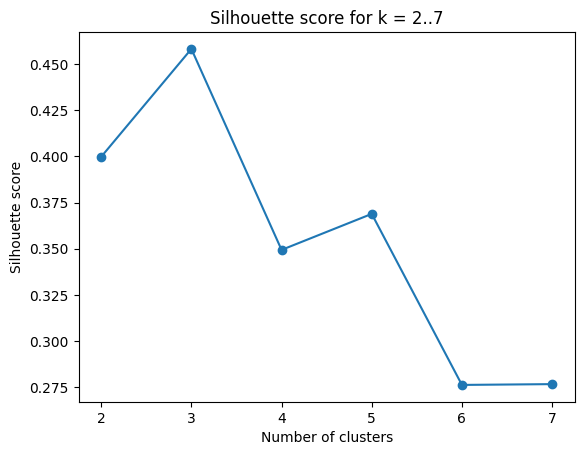

In [ ]:
# YOUR CODE — Task 2: scale, k = 2..7 sweep, silhouette line plot.

Xs = StandardScaler().fit_transform(df[spend_cols])

silhouette_scores = []
for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    labels = kmeans.labels_
    silhouette_scores.append(silhouette_score(Xs, labels))

plt.plot(range(2, 8), silhouette_scores, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.title('Silhouette score for k = 2..7')
plt.show()

## Task 3 of 5 — Choose k and defend it — YOUR ANSWER

Silhouette measures geometry, not usefulness. Your Task 1 answer may want more groups than the geometry's favorite.

**TODO (3–5 sentences):** Which k do you choose? Defend it against **both** the silhouette plot **and** your business question — and say explicitly what you traded away (e.g., "k=3 costs a little silhouette versus k=2 but gives the sales team a mid-size segment they can actually use").


## Task 4 of 5 — Profile the clusters and name them

In code:

1. Refit `KMeans` at your chosen k (same `n_init=10, random_state=42`) and attach the labels: `df["cluster"] = labels`.
2. Build the **profile table**: mean spend per cluster for the six columns, **plus each cluster's size**.
3. Cross-tab clusters against `Channel` as the honesty check: did the clustering rediscover horeca vs retail, or something else?

**Hints.** Profile: `df.groupby("cluster")[spend_cols].mean().round(0)` and `df["cluster"].value_counts()` · cross-tab: `pd.crosstab(df["cluster"], df["Channel"])`.

**Checkpoint.** At k=3 the table typically shows one **Grocery/Milk/Detergents-heavy** cluster (mostly `Channel` 2 — retail), one **Fresh-heavy** cluster (mostly horeca), and one much smaller big-spender group. Your exact split may differ — read *your* table.


In [ ]:
# YOUR CODE — Task 4: refit at your k, profile table with sizes, crosstab vs Channel.

raise NotImplementedError("Task 4: delete this line and write your code")

### Task 4 (written) — name the clusters — YOUR ANSWER

**TODO:** One line per cluster: a **business name** (not "Cluster 0"), its size, and the one row of evidence from your profile table that justifies the name. Example shape: *"Corner-store staples (n≈210): highest Grocery and Detergents_Paper spend, almost all retail channel."*


## Task 5 of 5 — Memo (≤1 page) — YOUR ANSWER

For the manager from your Task 1 answer. Replace each **TODO**.

### What the groups are and what to do with them

**TODO:** 3–5 sentences. Your named clusters and the concrete action each one gets (contract, tier, route, …).

### What this clustering cannot promise

**TODO:** 2–3 sentences. Silhouette preferred a different k, spend ≠ profitability, groups can shift next quarter — pick the caveat that is most real for your story.

### One way this could mislead

**TODO:** 2–4 sentences. Be specific: treating cluster labels as fixed truth, a cluster acting as a proxy for a protected group, chasing a segment that is an artifact of scaling…

### AI disclosure

**TODO:** Tool + what it did, or "I did not use AI."


## Before you submit

- [ ] File renamed to `CS6470_A5_LastName_FirstName.ipynb`
- [ ] **Runtime → Restart and run all** — every cell ran, no errors, no `NotImplementedError` anywhere
- [ ] All 5 tasks done: every `# YOUR CODE` cell has your code, every **YOUR ANSWER** / **TODO** prompt has your words
- [ ] Memo written in the Markdown cells above (it stays inside this notebook — no separate PDF)
- [ ] AI-use disclosure filled in

Upload the `.ipynb` file to this assignment on Canvas (in Colab: File → Download → Download .ipynb).

Integrity: the notebook and memo must be yours. AI may help explain an error; it may not be the submitted analysis.
